# Cell annotation with SOBER

Transfer coarse cell-type labels from three real **training reference regions** to a **patient-held-out internal-validation query region** using the epoch-10 frozen student. All regions come from UPMC-HNC and share the same marker panel.

We use 64 reference centers per coarse class (640 total) and 128 query centers, retaining complete regions for normalization and neighborhoods. We refined the reference design after inspecting the initial example. These scores demonstrate label transfer; they are not an independent benchmark or the manuscript's full-atlas result.

In [1]:
from pathlib import Path
import copy
import json
import sys
import platform
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sober/config.py").is_file())
sys.path.insert(0, str(ROOT))
from sober.checkpoint import load_checkpoint, file_sha256
from sober.data_loader import SpatialBiomarkerDataset

device = "cpu"
torch.set_num_threads(2)
model_info = json.loads((ROOT / "models/epoch10.json").read_text())
model, checkpoint = load_checkpoint(ROOT / "checkpoints/sober_epoch10.pth", device=device,
                                    expected_sha256=model_info["sha256"])
manifest = json.loads((ROOT / "examples/data/manifest.json").read_text())
example = manifest["downstream_examples"]
split_rows = {(r["study"], r["region"]): r for r in example["recorded_split"]["regions"]}
assert example["recorded_split"]["source_sha256"] == checkpoint["provenance"]["training_split_sha256"]
SEED, BATCH_SIZE = 42, 16
N_QUERY, REFERENCE_PER_CLASS, K = 128, 64, 10
%matplotlib inline
plt.rcParams.update({"font.size": 10, "figure.dpi": 120,
                     "axes.spines.top": False, "axes.spines.right": False})
print(f"Epoch {checkpoint['epoch']} student | {device} | PyTorch {torch.__version__}")
from sober.evaluation import verify_example_files
from sober.cell_type_normalize import apply_cell_type_normalization
from sober.evaluation import (sample_neighborhoods, sample_reference_neighborhoods,
                              extract_embeddings, predict_cell_types, annotation_metrics)
from sklearn.metrics import confusion_matrix

Loaded 41 biomarkers from sober/assets/biomarker_sequences.csv
Loaded 1282 biomarker aliases
Building biomarker vocabulary using learnable method...
Processing 41 valid biomarkers (EMPTY ones filtered out)
Building learnable embeddings...


Epoch 10 student | cpu | PyTorch 2.15.0


## Load reference and query

The reference combines three complete training regions (5,398 cells). The query is `UPMC_c005_v001_r001_reg028` (1,673 cells). Partition membership was checked against the epoch-10 patient split, which records no patient overlap. Additional reference regions were selected for training-label coverage relative to data size, without using query labels or model predictions. See [data provenance](../examples/data/README.md).

Annotations use the original `95-5-4` version and SOBER's coarse label mapping. Unmapped centers are excluded from this labeled evaluation, but remain available as neighbors. Query annotations are used to select evaluable centers and score predictions; they are not supplied to KNN fitting.

In [2]:
query_record = example["query"]
reference_records = [next(r for r in manifest["examples"] if r["folder"] == example["reference_folder"]),
                     *example["annotation_reference"]["additional_regions"]]
verify_example_files(ROOT / "examples/data", [*reference_records, query_record])
reference_roles = [split_rows[(r["study"], r["region"])] for r in reference_records]
query_role = split_rows[(query_record["study"], query_record["region"])]
assert all(r["partition"] == "train" for r in reference_roles)
assert query_role["partition"] == "validation"
assert query_role["patient_group_sha256"] not in {r["patient_group_sha256"] for r in reference_roles}

data_config = copy.deepcopy(model.config)
data_config.use_cell_types = True
data_config.cell_type_mapping_file = str(ROOT / "sober/assets/cell_type_mappings.csv")
assert Path(data_config.cell_type_mapping_file).read_text() == checkpoint["assets"]["cell_type_mapping_file"]["text"]
reference_data = SpatialBiomarkerDataset(ROOT / "examples/data", data_config)
additional_data = SpatialBiomarkerDataset(ROOT / "examples/reference", data_config)
query_data = SpatialBiomarkerDataset(ROOT / "examples/downstream", data_config)
for data in (reference_data, additional_data, query_data):
    apply_cell_type_normalization(data, verbose=False)

available = {(r["study_name"], r["region_name"]): r
             for r in [*reference_data.regions, *additional_data.regions]}
references = [available[(r["study"], r["region"])] for r in reference_records]
query = next(r for r in query_data.regions if (r["study_name"], r["region_name"]) == (query_record["study"], query_record["region"]))
assert all(r["region_name"] != query["region_name"] for r in references)
assert all(r["biomarkers"] == query["biomarkers"] for r in references)
assert set(query["biomarkers"]) <= set(checkpoint["biomarker_vocab"])
display(pd.DataFrame([
    {"role": role, "region": region["region_name"], "cells": region["num_cells"],
     "mapped centers": sum(bool(h and h[0]) for h in region["cell_type_hierarchy"])}
    for role, region in [("reference", r) for r in references] + [("query", query)]
]))

Loaded cell-type version table: 22 studies from sober/assets/study_celltype_final.tsv
Loaded 3 regions; skipped 0 small regions
Loaded cell-type version table: 22 studies from sober/assets/study_celltype_final.tsv
Loaded 2 regions; skipped 0 small regions
Loaded cell-type version table: 22 studies from sober/assets/study_celltype_final.tsv
Loaded 1 regions; skipped 0 small regions


,role,region,cells,mapped centers
0,reference,UPMC_c001_v001_r001_reg039,1670,1628
1,reference,UPMC_c002_v001_r001_reg009,1489,1329
2,reference,UPMC_c002_v001_r001_reg035,2239,2207
3,query,UPMC_c005_v001_r001_reg028,1673,1382


## Extract frozen cell representations

Each unmasked neighborhood produces a 512-dimensional center embedding. The reference uses 64 centers per coarse class, sampled without replacement across the training regions. This balanced reference keeps each class represented for K=10 voting; it is a tutorial design choice, not the manuscript's full-atlas sampling protocol.

Query sampling follows the research code: take one center per mapped class, then fill the budget randomly without replacement. The query region, 128 query centers and seed remain fixed.

In [3]:
reference_samples = sample_reference_neighborhoods(references, model.config, n_per_class=REFERENCE_PER_CLASS, seed=SEED)
query_samples = sample_neighborhoods(query, model.config, N_QUERY, seed=SEED, labeled_only=True)
reference_x = extract_embeddings(model, reference_samples, batch_size=BATCH_SIZE)
query_x = extract_embeddings(model, query_samples, batch_size=BATCH_SIZE)
reference_y = np.array([s["cell_type_hierarchy"][0][0] for s in reference_samples])
query_y = np.array([s["cell_type_hierarchy"][0][0] for s in query_samples])
reference_counts = pd.Series(reference_y).value_counts()
assert (reference_counts == REFERENCE_PER_CLASS).all(), "Insufficient cells for a balanced reference"
assert reference_counts.min() >= K, "Each tutorial reference class needs at least K cells"
assert np.isfinite(reference_x).all() and np.isfinite(query_x).all()
print("Reference:", reference_x.shape, "| Query:", query_x.shape)
display(pd.DataFrame({"reference": pd.Series(reference_y).value_counts(),
                      "query": pd.Series(query_y).value_counts()}).fillna(0).astype(int))

Reference: (640, 512) | Query: (128, 512)


,reference,query
B cells,64,5
Endothelial cells,64,7
Epithelial cells,64,57
Granulocytes,64,3
Macrophages,64,12
Mast cells,64,2
Monocytes,64,3
NK cells,64,4
Stromal cells,64,7
T cells,64,28


## Transfer labels and evaluate

Use L2-normalized embeddings with **10-neighbor cosine KNN and uniform voting**, as in the research evaluation. No encoder weights are updated. Accuracy and support-weighted F1 are computed over every selected query cell, including classes absent from this small reference.

In [4]:
predicted = predict_cell_types(reference_x, reference_y, query_x, k=K)
scores = annotation_metrics(query_y, predicted)
unseen = sorted(set(query_y) - set(reference_y))
print("Query classes absent from the reference:", unseen or "none")
display(pd.DataFrame([scores]).round(4))
predictions = pd.DataFrame({
    "study": query["study_name"], "region": query["region_name"],
    "center_idx": [s["original_center_idx"] for s in query_samples],
    "cell_id": [str(s["cell_ids"][0]) for s in query_samples],
    "observed": query_y, "predicted": predicted,
})
predictions.head()

Query classes absent from the reference: none


,n_cells,accuracy,f1_weighted
0,128,0.9688,0.9695


,study,region,center_idx,cell_id,observed,predicted
0,s240,UPMC_c005_v001_r001_reg028,43,1109956,Epithelial cells,Epithelial cells
1,s240,UPMC_c005_v001_r001_reg028,64,1109977,Epithelial cells,Epithelial cells
2,s240,UPMC_c005_v001_r001_reg028,65,1109978,Epithelial cells,Epithelial cells
3,s240,UPMC_c005_v001_r001_reg028,78,1109991,Epithelial cells,Epithelial cells
4,s240,UPMC_c005_v001_r001_reg028,82,1109995,Epithelial cells,Epithelial cells


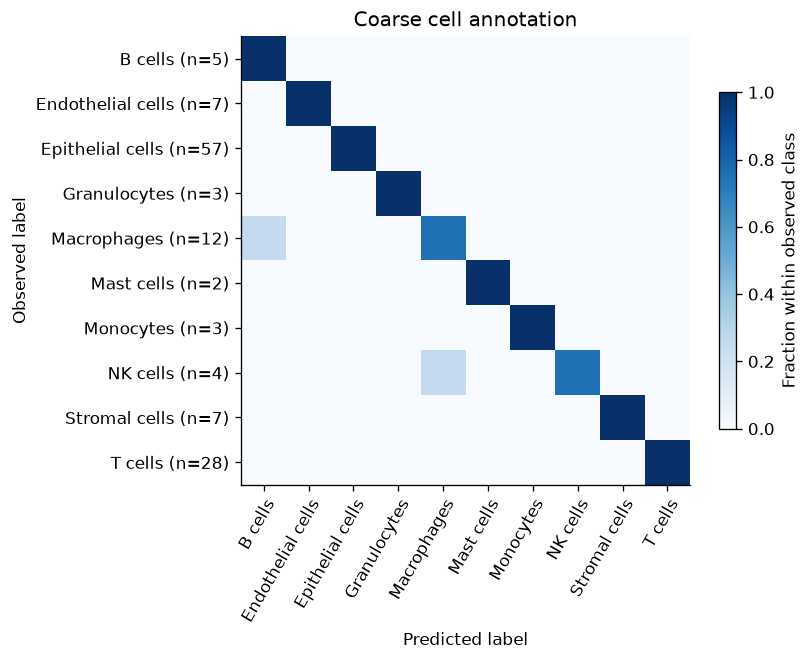

In [5]:
labels = sorted(set(query_y) | set(predicted))
counts = confusion_matrix(query_y, predicted, labels=labels)
fractions = np.divide(counts, counts.sum(axis=1, keepdims=True),
                      out=np.zeros_like(counts, dtype=float), where=counts.sum(axis=1, keepdims=True) != 0)
fig, ax = plt.subplots(figsize=(7, 5.4), layout="constrained")
im = ax.imshow(fractions, cmap="Blues", vmin=0, vmax=1)
ax.set(xticks=range(len(labels)), yticks=range(len(labels)),
       xticklabels=labels, yticklabels=[f"{label} (n={n})" for label, n in zip(labels, counts.sum(axis=1))],
       xlabel="Predicted label", ylabel="Observed label",
       title="Coarse cell annotation")
plt.setp(ax.get_xticklabels(), rotation=60, ha="right", rotation_mode="anchor")
fig.colorbar(im, ax=ax, label="Fraction within observed class", shrink=0.75)
plt.show()

## Save the outputs

Save the selected cells, embeddings, predictions and settings. These outputs can be inspected without rerunning the encoder.

In [6]:
output = ROOT / "checkpoints/cell_annotation_demo"
output.mkdir(parents=True, exist_ok=True)
fig.savefig(output / "confusion_matrix.png", dpi=160, bbox_inches="tight")
predictions.to_csv(output / "predictions.csv", index=False)
pd.DataFrame([scores]).to_csv(output / "metrics.csv", index=False)
pd.DataFrame(counts, index=labels, columns=labels).to_csv(output / "confusion_counts.csv")
np.savez_compressed(
    output / "embeddings.npz", reference=reference_x, query=query_x,
    reference_labels=reference_y, query_labels=query_y,
    reference_cell_ids=np.array([str(s["cell_ids"][0]) for s in reference_samples]),
    reference_regions=np.array([s["region_name"] for s in reference_samples]),
    query_cell_ids=predictions["cell_id"].to_numpy(dtype=str),
)
run = {
    "checkpoint_sha256": model_info["sha256"],
    "data_manifest_sha256": file_sha256(ROOT / "examples/data/manifest.json"),
    "environment": {"python": platform.python_version(), "device": device,
                    "packages": {p: version(p) for p in ("torch", "numpy", "pandas", "scipy", "scikit-learn")}},
    "weights": "student", "seed": SEED, "batch_size": BATCH_SIZE,
    "reference_regions": [r["region_name"] for r in references], "query_region": query["region_name"],
    "reference_sampling": {"strategy": "per_class", "centers_per_class": REFERENCE_PER_CLASS, "seed": SEED},
    "reference_patient_groups": [r["patient_group_sha256"] for r in reference_roles],
    "query_patient_group": query_role["patient_group_sha256"],
    "reference_partition": "train", "query_partition": "internal_validation",
    "reference_centers": [{"region": s["region_name"], "center_idx": s["original_center_idx"],
                           "cell_id": str(s["cell_ids"][0])} for s in reference_samples],
    "query_center_indices": [s["original_center_idx"] for s in query_samples],
    "k": K, "metric": "cosine", "weights_knn": "uniform", "label_level": "coarse",
}
(output / "evaluation.json").write_text(json.dumps(run, indent=2) + "\n")
print("Saved embeddings, predictions, metrics, confusion counts and evaluation settings")

Saved embeddings, predictions, metrics, confusion counts and evaluation settings
